In [65]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from pathlib import Path
from scipy.spatial import cKDTree
import seaborn as sns
from utils import construct_path, read_feather_gcs
from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
pd.set_option('display.max_rows', 200)

In [66]:
### LOAD DATA
DATASET = "malecns_09"
SUBSET_NAME = "optic"
DATA_PATH = "connectome_data"
pin_data  = 'pin_data'

dataset_base = DATASET.split("_")[0]  # "malecns"

if SUBSET_NAME is not None:
    edgelist_path = (
        f"{DATA_PATH}/{dataset_base}/"
        f"{dataset_base}_{SUBSET_NAME}_{DATASET}_{SUBSET_NAME}_simple_edgelist.feather"
    )
else:
    edgelist_path = construct_path(DATA_PATH, DATASET, "edgelist_simple")
    print("Using full dataset")

meta_path = construct_path(DATA_PATH, DATASET, "meta")
# print(f"Meta path: {meta_path}")
print(f"Edgelist path: {edgelist_path}")

#Column pins from Nern et al 2025. Nature
#NOTE: !!!!!!
#Coordinate systems
# X Y Z
# Data from neuprint uses x y z coordinates. Here is a place to describe that coordinate system.

# Hex1 Hex2
# Omatidia in the Drosophila compound eye are arranged in what resembles a hexagonal grid. 
# Each individual omatidia can be uniqueliy identified along the 3 hexagonal axis hex1, hex2, and hex3. 
# In fact, any two of these coordinates is enough to identify the location. 
# The hex1 hex2 coordinates used in the neuprint database and in our analysis are positive numbers. 
# The origin of the coordinate system is arbitrarily located outside of the eyemap.

# P Q V
# A biologically more relevant coordinate system uses the center of the eye as the origin 
# of the P and Q coordinate system. We define the hex1 hex2 coordintes [18 19] as our origin for P Q.

# The H and V-axis use the same origin with V representing the virtual hex3. 
# The H axis is somewhat parallel to the perceived horizon.

meta = read_feather_gcs(meta_path, gcs_fs=None)
meta["malecns_09_id"] = meta["malecns_09_id"].astype("int64")
ct1_node = meta.query("cell_type == 'CT1' and side =='left'").copy().reset_index(drop=True)
ct1_node.rename(columns={"optic_lobe_hex_1": "hex_1",
                               "optic_lobe_hex_2": "hex_2"
                               }, inplace=True)
edgelist = read_feather_gcs(edgelist_path, gcs_fs=None)
edgelist = edgelist[edgelist["count"] > 3].copy().reset_index(drop=True)


Edgelist path: connectome_data/malecns/malecns_optic_malecns_09_optic_simple_edgelist.feather
✓ Loaded 165,114 rows
✓ Loaded 6,629,951 rows


In [67]:
ct1_node

,malecns_09_id,region,neuromere,side,hemilineage,nerve,tract,flow,super_class,cell_class,cell_sub_class,cell_type,fafb_cell_type,hemibrain_cell_type,manc_cell_type,neurotransmitter_predicted,neurotransmitter_score,cell_function,cell_function_detailed,body_part_sensory,body_part_effector,sexually_dimorphic,hex_1,hex_2,status,_locked,_locked_by,_archived,_creator,_ctime,_last_modifier,_mtime,_id
0,10009,optic_lobe,None,left,None,None,None,intrinsic,optic_lobe_intrinsic,lobula_medulla_amacrine,None,CT1,CT1,CT1,None,gaba,0.860479,None,None,None,None,isomorphic,None,None,Roughly traced,None,None,True,498faaeec7594eb1af1d548baefecba6@auth.local,2026-02-27 01:07:59.484000+00:00,498faaeec7594eb1af1d548baefecba6@auth.local,2026-04-27 14:35:34.020000+00:00,whB7VwZpQZW05uAnxSP1Sg


In [68]:
cols_to_keep= ['malecns_09_id', 'side', 'cell_type','neurotransmitter_predicted', 'neurotransmitter_score',
                'hex_1', 'hex_2',
                ]
ct1_node = ct1_node[cols_to_keep].copy()


In [69]:
data_dir = Path("connectome_data/processed")
col_nodes = pd.read_feather(data_dir / "columnar_nodes.feather")
T4_T5_nodes = pd.read_feather(data_dir / "T4_T5_home_columns.feather")
# nodes_df = pd.concat([col_nodes, T4_T5_nodes, ct1_node], ignore_index=True).drop_duplicates("malecns_09_id", keep="last").copy()
nodes_df = pd.concat([col_nodes, T4_T5_nodes], 
                     ignore_index=True).drop_duplicates(
                         "malecns_09_id", keep="last").copy() #lets skip ct1 to not double count when creating edgelist


ct1_edgelist = pd.read_feather(data_dir / "ct1_columnar_edges.feather").drop(columns=['ct1_direction', 'neuropil'])
ct1_edgelist['pre_side'] = 'right'
ct1_edgelist['post_side'] = 'right'

In [70]:
ct1_edgelist

,pre,post,pre_cell_type,post_cell_type,count,source_hex_1,source_hex_2,source_p,source_q,target_hex_1,target_hex_2,target_p,target_q,dp,dq,edge_nt,edge_nt_score,pre_side,post_side
0,10009,34329,CT1,Mi1,4,18.0,10.0,0.0,-9.0,18.0,10.0,0.0,-9.0,0.0,0.0,gaba,0.985038,right,right
1,10009,35572,CT1,Mi1,4,12.0,28.0,-6.0,9.0,12.0,28.0,-6.0,9.0,0.0,0.0,gaba,0.943943,right,right
2,10009,37680,CT1,Mi1,5,24.0,26.0,6.0,7.0,24.0,26.0,6.0,7.0,0.0,0.0,gaba,0.923089,right,right
3,10009,38220,CT1,T5c,12,26.0,15.0,8.0,-4.0,26.0,14.0,8.0,-5.0,0.0,-1.0,gaba,0.912660,right,right
4,10009,38220,CT1,T5c,7,27.0,15.0,9.0,-4.0,26.0,14.0,8.0,-5.0,-1.0,-1.0,gaba,0.891790,right,right
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17855,554311,10009,T4d,CT1,4,25.0,10.0,7.0,-9.0,25.0,10.0,7.0,-9.0,0.0,0.0,acetylcholine,0.995642,right,right
17856,554447,10009,Tm9,CT1,25,3.0,7.0,-15.0,-12.0,3.0,7.0,-15.0,-12.0,0.0,0.0,acetylcholine,0.996686,right,right
17857,554753,10009,T4b,CT1,4,10.0,27.0,-8.0,8.0,10.0,27.0,-8.0,8.0,0.0,0.0,acetylcholine,0.997756,right,right
17858,579914,10009,Tm9,CT1,6,7.0,6.0,-11.0,-13.0,7.0,5.0,-11.0,-14.0,0.0,-1.0,acetylcholine,0.998023,right,right


## Annotated edgelist

In [71]:
# ids = set(nodes_df["malecns_09_id"])
ids = nodes_df["malecns_09_id"].unique()
edges_df = edgelist.query("pre in @ids and post in @ids").copy().reset_index(drop=True)
edges_df["pre"] = edges_df["pre"].astype("int64")
edges_df["post"] = edges_df["post"].astype("int64")

post_info = nodes_df[
    ["malecns_09_id", "cell_type", "hex_1", "hex_2", "p", "q", "side"]
].rename(
    columns={
        "malecns_09_id": "post",
        "cell_type": "post_cell_type",
        "hex_1": "target_hex_1",
        "hex_2": "target_hex_2",
            "p": "target_p",
            "q": "target_q",
        "side": "post_side",
    }
    )

pre_info = nodes_df[
    ["malecns_09_id", "cell_type", "hex_1", "hex_2", "p", "q", "side", "neurotransmitter_predicted", "neurotransmitter_score"]
].rename(
    columns={
        "malecns_09_id": "pre",
        "cell_type": "pre_cell_type",
        "hex_1": "source_hex_1",
        "hex_2": "source_hex_2",
        "p": "source_p",
        "q": "source_q",
        "side": "pre_side",
        "neurotransmitter_predicted": "edge_nt",
        "neurotransmitter_score": "edge_nt_score",
    }
)
edges_annot = edges_df.merge(
    post_info,
    on="post",
    how="left"
).merge(
    pre_info,
    on="pre",
    how="left"
)
edges_annot["dp"] =  edges_annot['target_p'] - edges_annot['source_p']
edges_annot["dq"] =  edges_annot['target_q'] - edges_annot['source_q']

front_cols = ['pre', 'post', 'pre_cell_type', 'post_cell_type', 'count', "dp", "dq"] #nt_predicted', 'nt_score']
# count	neuropil	source_hex_1	source_hex_2	source_p	source_q	target_hex_1	target_hex_2	target_p	target_q	dp	dq	edge_nt	edge_nt_score

# 2. Reorder by adding the rest of the columns automatically
edges_annot = edges_annot[front_cols + [c for c in edges_annot.columns if c not in front_cols]]

In [72]:
edges = pd.concat([edges_annot, ct1_edgelist], ignore_index=True).copy() #lets skip ct1 to not double count when creating edgelist
edges["sign"] = np.nan #Note some T4/5 and known nt synapses maybe incorrectly classified

edges.loc[edges["edge_nt"].eq("acetylcholine"), "sign"] = 1.0
edges.loc[edges["edge_nt"].isin(["gaba", "glutamate"]), "sign"] = -1.0
edges = edges[edges['count'] > 4.0]
edges

,pre,post,pre_cell_type,post_cell_type,count,dp,dq,norm,total_input,target_hex_1,target_hex_2,target_p,target_q,post_side,source_hex_1,source_hex_2,source_p,source_q,pre_side,edge_nt,edge_nt_score,sign
0,21598,31004,L2,L1,5,0.0,0.0,0.017065,293.0,32.0,21.0,14.0,2.0,right,32.0,21.0,14.0,2.0,right,acetylcholine,0.935050,1.0
1,76831,26444,L5,L2,10,0.0,0.0,0.034483,290.0,32.0,20.0,14.0,1.0,right,32.0,20.0,14.0,1.0,right,acetylcholine,0.957103,1.0
2,76831,23877,L5,L1,23,0.0,0.0,0.130682,176.0,32.0,20.0,14.0,1.0,right,32.0,20.0,14.0,1.0,right,acetylcholine,0.957103,1.0
3,545608,26444,C3,L2,69,0.0,0.0,0.237931,290.0,32.0,20.0,14.0,1.0,right,32.0,20.0,14.0,1.0,right,gaba,0.813528,-1.0
4,49458,21598,C3,L2,65,0.0,0.0,0.166240,391.0,32.0,21.0,14.0,2.0,right,32.0,21.0,14.0,2.0,right,gaba,0.818378,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178000,546619,10009,Tm1,CT1,7,0.0,0.0,NaN,NaN,27.0,17.0,9.0,-2.0,right,27.0,17.0,9.0,-2.0,right,acetylcholine,0.999533,1.0
178001,547644,10009,LC14b,CT1,6,NaN,NaN,NaN,NaN,32.0,18.0,14.0,-1.0,right,NaN,NaN,NaN,NaN,right,acetylcholine,0.990604,1.0
178005,554447,10009,Tm9,CT1,25,0.0,0.0,NaN,NaN,3.0,7.0,-15.0,-12.0,right,3.0,7.0,-15.0,-12.0,right,acetylcholine,0.996686,1.0
178007,579914,10009,Tm9,CT1,6,0.0,-1.0,NaN,NaN,7.0,5.0,-11.0,-14.0,right,7.0,6.0,-11.0,-13.0,right,acetylcholine,0.998023,1.0


## Average kernels

In [73]:
T4s= ['T4a', 'T4b', 'T4c', 'T4d']
T5s = ['T5a', 'T5b', 'T5c', 'T5d']
T4_inputs = edges.query("post_cell_type in @T4s").reset_index(drop=True)
T5_inputs = edges.query("post_cell_type in @T5s").reset_index(drop=True)

In [74]:
T4_inputs

,pre,post,pre_cell_type,post_cell_type,count,dp,dq,norm,total_input,target_hex_1,target_hex_2,target_p,target_q,post_side,source_hex_1,source_hex_2,source_p,source_q,pre_side,edge_nt,edge_nt_score,sign
0,143800,120266,Mi9,T4c,24,1.0,1.0,0.090566,265.0,9.0,27.0,-9.0,8.0,right,8.0,26.0,-10.0,7.0,right,glutamate,0.700617,-1.0
1,143800,134894,Mi9,T4b,17,-1.0,-2.0,0.062963,270.0,7.0,24.0,-11.0,5.0,right,8.0,26.0,-10.0,7.0,right,glutamate,0.700617,-1.0
2,141645,125269,Mi9,T4b,26,1.0,0.0,0.119266,218.0,14.0,32.0,-4.0,13.0,right,13.0,32.0,-5.0,13.0,right,glutamate,0.698464,-1.0
3,94777,125269,Mi4,T4b,6,1.0,0.0,0.027523,218.0,14.0,32.0,-4.0,13.0,right,13.0,32.0,-5.0,13.0,right,gaba,0.815785,-1.0
4,143800,125314,Mi9,T4b,15,0.0,0.0,0.068182,220.0,8.0,26.0,-10.0,7.0,right,8.0,26.0,-10.0,7.0,right,glutamate,0.700617,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34165,10009,542541,CT1,T4d,6,1.0,0.0,NaN,NaN,35.0,32.0,17.0,13.0,right,34.0,32.0,16.0,13.0,right,gaba,0.979873,-1.0
34166,10009,546260,CT1,T4a,7,1.0,0.0,NaN,NaN,35.0,31.0,17.0,12.0,right,34.0,31.0,16.0,12.0,right,gaba,0.929167,-1.0
34167,10009,547912,CT1,T4a,5,1.0,-1.0,NaN,NaN,6.0,2.0,-12.0,-17.0,right,5.0,3.0,-13.0,-16.0,right,gaba,0.966784,-1.0
34168,10009,554192,CT1,T4a,11,0.0,0.0,NaN,NaN,32.0,36.0,14.0,17.0,right,32.0,36.0,14.0,17.0,right,gaba,0.925113,-1.0


In [75]:

def hex_distance(dp, dq):
    return np.maximum.reduce([
        np.abs(dp),
        np.abs(dq),
        np.abs(dq - dp)
    ])


def hex_offsets(radius):
    rows = []

    for dp in range(-radius, radius + 1):
        for dq in range(-radius, radius + 1):
            if hex_distance(dp, dq) <= radius:
                rows.append((dp, dq))

    return pd.DataFrame(rows, columns=["dp", "dq"])

def pq_to_xy(p, q, hexsize=1.0, rotate=-np.pi/6):
    """
    Map Zhao (p,q) coords to 2D xy for plotting.
    Matches your Julia convention: (p,q)->(q,-p) then rotate by -30°.
    """
    a = q
    b = -p

    # pointy-top axial -> pixel
    x = hexsize * np.sqrt(3) * (a + b/2)
    y = hexsize * 1.5 * b

    if rotate is not None:
        c, s = np.cos(rotate), np.sin(rotate)
        xr = c*x - s*y
        yr = s*x + c*y
        return xr, yr

    return x, y

def mean_spatial_kernel_zero_filled(
    edges,
    pre_type="Mi1",
    post_type="T4b",
    same_side=True,
    radius=3
):
    df = edges.query(
        "pre_cell_type == @pre_type and post_cell_type == @post_type"
    ).copy()

    if same_side:
        df = df.query("pre_side == post_side").copy()

    df["signed_count"] = df["count"] * df["sign"]

    offsets = hex_offsets(radius)

    if post_type == "CT1":
        # Treat CT1 as many local column compartments.
        # Each CT1 target column acts like a pseudo-postsynaptic unit.
        post_cells = (
            df[["target_p", "target_q", "post_side"]]
            .dropna(subset=["target_p", "target_q"])
            .drop_duplicates()
            .copy()
            .rename(columns={
                "target_p": "ct1_target_p",
                "target_q": "ct1_target_q",
            })
        )

        post_cells["pseudo_post"] = (
            post_cells["ct1_target_p"].astype(int).astype(str)
            + "_"
            + post_cells["ct1_target_q"].astype(int).astype(str)
        )

        full_index = (
            post_cells[["pseudo_post", "post_side"]]
            .assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["target_p", "target_q", "dp", "dq"])
            .assign(
                pseudo_post=lambda d: (
                    d["target_p"].astype(int).astype(str)
                    + "_"
                    + d["target_q"].astype(int).astype(str)
                ),
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["pseudo_post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum"),
            )
        )

        full = full_index.merge(
            observed,
            on=["pseudo_post", "dp", "dq"],
            how="left"
        )

    else:
        # Original behavior: normalize over postsynaptic cells
        post_cells = (
            edges.query("post_cell_type == @post_type")
            [["post", "target_p", "target_q", "post_side"]]
            .drop_duplicates()
            .copy()
        )

        if same_side:
            post_cells = post_cells[
                post_cells["post_side"].isin(df["post_side"].dropna().unique())
            ]

        full_index = (
            post_cells.assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["dp", "dq"])
            .assign(
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum")
            )
        )

        full = full_index.merge(
            observed,
            on=["post", "dp", "dq"],
            how="left"
        )

    full["count"] = full["count"].fillna(0)
    full["signed_count"] = full["signed_count"].fillna(0)

    kernel = (
        full
        .groupby(["dp", "dq"], as_index=False)
        .agg(
            mean_count=("count", "mean"),
            mean_signed_count=("signed_count", "mean")
        )
        .sort_values("mean_signed_count", ascending=False)
    )

    return kernel, full

mi1_t4b_kernel, mi1_t4b_full = mean_spatial_kernel_zero_filled(
    edges,
    pre_type="CT1",
    post_type="T5b")

mi1_t4b_kernel

,dp,dq,mean_count,mean_signed_count
0,-3,-3,0.000000,0.000000
1,-3,-2,0.000000,0.000000
3,-3,0,0.000000,0.000000
4,-2,-3,0.000000,0.000000
10,-1,-2,0.000000,0.000000
33,3,0,0.000000,0.000000
9,-1,-3,0.000000,0.000000
15,0,-3,0.000000,0.000000
16,0,-2,0.000000,0.000000
17,0,-1,0.000000,0.000000


<Axes: title={'center': 'Mi1 to T4b mean signed synapse count'}>

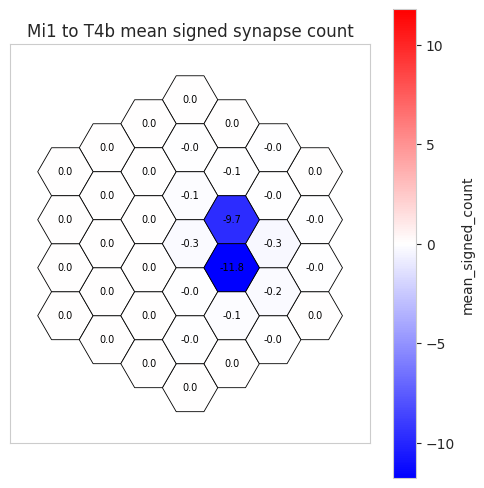

In [76]:
from matplotlib.patches import RegularPolygon
from matplotlib.colors import Normalize
import matplotlib.pyplot as plt
import numpy as np

    

def plot_spatial_kernel_hex(
    kernel,
    value_col="mean_signed_syn_count",
    *,
    radius=None,
    hexsize=1.0,
    cmap="bwr",
    norm=None,
    mirror_x=False,
    mirror_y=False,
    plot_labels=True,
    title=None,
    ax=None,
    add_colorbar=False,
    fs=14
):
    """
    Plot mean spatial kernel using dp/dq as relative hex coordinates.
    Red = positive signed synapses
    Blue = negative signed synapses
    White = zero
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure
        
    kernel = kernel.copy()

    kernel = kernel.dropna(subset=["dp", "dq", value_col])
    kernel["dp"] = kernel["dp"].astype(int)
    kernel["dq"] = kernel["dq"].astype(int)

    if radius is not None:
        dist = hex_distance(kernel["dp"], kernel["dq"])
        kernel = kernel[dist <= radius].copy()

    ax.set_aspect("equal")

    cmap_obj = plt.get_cmap(cmap)

    if norm is None:
        vmax = np.nanmax(np.abs(kernel[value_col].to_numpy()))
        norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    x, y = pq_to_xy(
        kernel["dp"].to_numpy(),
        kernel["dq"].to_numpy(),
        hexsize=hexsize
    )

    if mirror_x:
        x = -x
    if mirror_y:
        y = -y

    vals = kernel[value_col].to_numpy()

    for xi, yi, dp, dq, val in zip(
        x, y,
        kernel["dp"].to_numpy(),
        kernel["dq"].to_numpy(),
        vals
    ):
        ax.add_patch(
            RegularPolygon(
                (xi, yi),
                numVertices=6,
                radius=hexsize,
                orientation=np.pi / 6,
                facecolor=cmap_obj(norm(val)),
                edgecolor="black",
                linewidth=0.6
            )
        )

        if plot_labels:
            ax.text(
                xi, yi,
                # f"{dp},{dq}\n{val:.1f}",
                f"{val:.1f}",
                fontsize=7,
                ha="center",
                va="center",
                color="black"
            )

    pad = 2 * hexsize
    ax.set_xlim(x.min() - pad, x.max() + pad)
    ax.set_ylim(y.min() - pad, y.max() + pad)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    if title is None:
        title = value_col
    ax.set_title(title)

    if add_colorbar:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        fig.colorbar(sm, ax=ax, label=value_col)
    
    fig.tight_layout()

    return ax

# plot_spatial_kernel_hex(mi1_t4b_kernel, value_col="mean_signed_count", radius=4, cmap="bwr", title="Mi1 to T4b mean signed synapse count")

plot_spatial_kernel_hex(mi1_t4b_kernel, value_col="mean_signed_count", 
                        radius=4, cmap="bwr", add_colorbar=True,
                        title="Mi1 to T4b mean signed synapse count")

In [81]:
post_type = "T5b"
post_type_inputs = df = edges.query(
        "post_cell_type == @post_type"
    ).copy()
input_types = post_type_inputs['pre_cell_type'].unique()

value_col = "mean_signed_count"
# post_type = "T4b"

kernels = {}

for pre_type in input_types:
    kernel, full = mean_spatial_kernel_zero_filled(
        edges,
        pre_type=pre_type,
        post_type=post_type,
        radius=3
    )
    kernels[pre_type] = kernel

In [82]:
threshold = 0.1

kernel_strength = {
    pre_type: kernels[pre_type][value_col].abs().max()
    for pre_type in input_types
}

input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= threshold
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True
)

In [83]:
from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
all_vals = np.concatenate([
    k[value_col].to_numpy()
    for k in kernels.values()
])

vmax = np.nanmax(np.abs(all_vals))

# norm = TwoSlopeNorm(
#     vmin=-vmax,
#     vcenter=0,
#     vmax=vmax
# )

norm = SymLogNorm(
    linthresh=1,      # values between -1 and 1 are linear
    linscale=1,
    vmin=-vmax,
    vmax=vmax,
    base=10
)

/tmp/ipykernel_147036/2132709759.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


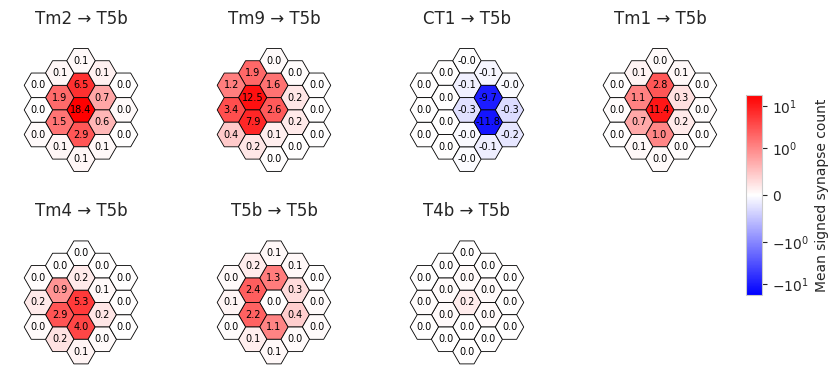

In [84]:
import math
n = len(input_types)
ncols = min(4, n)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(2 * ncols, 2 * nrows),
    squeeze=False
)

axes_flat = axes.flatten()

for ax, pre_type in zip(axes_flat, input_types):
    plot_spatial_kernel_hex(
        kernels[pre_type],
        value_col=value_col,
        radius=2,
        cmap="bwr",
        norm=norm,
        ax=ax,
        title=f"{pre_type} → {post_type}",
        plot_labels=True,
    )


for ax in axes_flat:
    ax.axis("off")

# Common colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])
plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]

cax = fig.add_axes([0.97, 0.25, 0.02, 0.5]) # [left, bottom, width, height]
cbar = fig.colorbar(
    sm,
    cax=cax,
    shrink=0.4,
    location="right",
    label="Mean signed synapse count"
)

# fig.suptitle(f"Signed spatial input kernels onto {post_type}", fontsize=16, y=1.02)

fig.tight_layout()
plt.show()